[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zjelveh/zjelveh.github.io/blob/master/files/ccjs418e_fall2026/8_datetime_operations.ipynb)

**IMPORTANT**: Save your own copy!
1. Click File → Save a copy in Drive
2. Rename it
3. Work in YOUR copy, not the original


---


# 8. Datetime Operations with Pandas
## CCJS 418E: Coding for Criminology

Today's Goals:
- Convert string dates to datetime objects
- Extract year, month, day from dates
- Filter data by date ranges
- Create time period indicators
- Use `.iloc` for position-based indexing
- Aggregate data by time periods
- Summarize arrests by month and quarter

Last class: We learned about groupby operations for aggregating data
Today: We learn to work with dates and analyze time-based patterns

**Research Context:**

In July 2014, Eric Garner died after an NYPD officer placed him in a chokehold during an arrest on Staten Island. In December, a grand jury declined to indict the officer, prompting widespread protests. [Background](https://www.law.columbia.edu/news/archive/fact-sheet-richmond-county-staten-island-grand-jury-eric-garner-homicide)

Later that month, two NYPD officers, Rafael Ramos and Wenjian Liu, were murdered. Amid conflict between police unions and city leadership, officers sharply reduced proactive enforcement, including arrests for low-level offenses. [Historical context](https://www.shortcutstv.com/wp-content/uploads/2020/11/sullivan-and-okeeffe.pdf)

We'll use arrest records to investigate:

**Key Research Question:** How did arrest patterns change during this period, and were the changes different for misdemeanor and felony arrests?

## Setup: Import Libraries and Load Data

We'll use NYPD arrest data from 2013-2015 to analyze enforcement patterns.

In [ ]:
# Show each result in a cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Load the data
df = pd.read_csv(filepath_or_buffer='https://raw.githubusercontent.com/zjelveh/zjelveh.github.io/refs/heads/master/files/ccjs418e_fall2025/nypd_arrests_2013_2015_garner.csv')

# Number of arrest records
len(df)

# Column names
df.columns

# First few rows
df.head()

## A Preview of What We Can Explore

This file contains felony and misdemeanor arrest records from New York City in 2013–2015. Each row records an arrest, with a date, borough, and offense category.

These two charts introduce the data and preview what you will learn to build over the next few classes.

The supplied preparation cell creates two summary tables for the charts. Run it once. We will work through date conversion, filtering, and grouping during the lessons that follow.


In [ ]:
# @title Supplied preparation for the two preview charts
preview_data = df[['ARREST_DATE', 'ARREST_BORO', 'LAW_CAT_CD']].copy()
preview_data['ARREST_DATE'] = pd.to_datetime(arg=preview_data['ARREST_DATE'])
preview_data['year_month'] = preview_data['ARREST_DATE'].dt.to_period(freq='M').dt.to_timestamp()

monthly_arrests = preview_data.groupby(by=['year_month']).size().reset_index(name='arrests')
monthly_arrests['arrests_per_day'] = monthly_arrests['arrests'] / monthly_arrests['year_month'].dt.days_in_month

preview_2014 = preview_data[preview_data['ARREST_DATE'].dt.year == 2014]
borough_arrests = preview_2014.groupby(by=['ARREST_BORO', 'LAW_CAT_CD']).size().reset_index(name='arrests')
borough_arrests['borough'] = borough_arrests['ARREST_BORO'].replace(to_replace={
    'B': 'Bronx', 'K': 'Brooklyn', 'M': 'Manhattan', 'Q': 'Queens', 'S': 'Staten Island'
})
borough_arrests['category'] = borough_arrests['LAW_CAT_CD'].replace(
    to_replace={'F': 'Felony', 'M': 'Misdemeanor'}
)


### How did arrest activity vary over time?

Each point shows the average number of recorded arrests per day during one calendar month. Notice the variation across months and the change around the end of 2014.

The plotting call names the table with `data=`, the horizontal-axis column with `x=`, and the vertical-axis column with `y=`.


<Axes: xlabel='year_month', ylabel='arrests_per_day'>

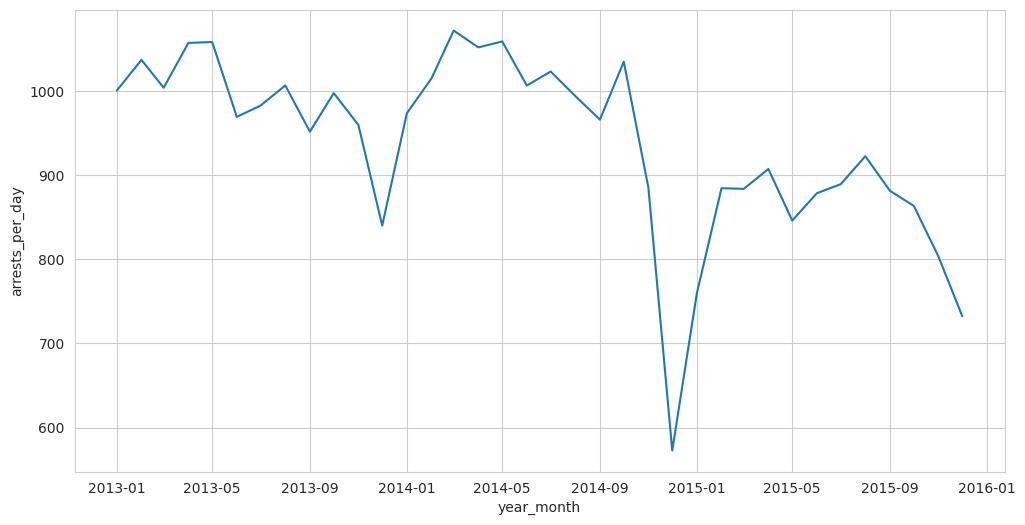

In [ ]:
sns.lineplot(
    data=monthly_arrests,
    x='year_month',
    y='arrests_per_day'
)


### How did arrest categories vary across boroughs?

Each pair of bars counts felony and misdemeanor arrests recorded in one borough during 2014. Compare the heights of the bars and the mix of the two categories across boroughs.

The same `data=`, `x=`, and `y=` pattern applies here. Adding `hue='category'` shows felony and misdemeanor arrests in different colors.


<Axes: xlabel='borough', ylabel='arrests'>

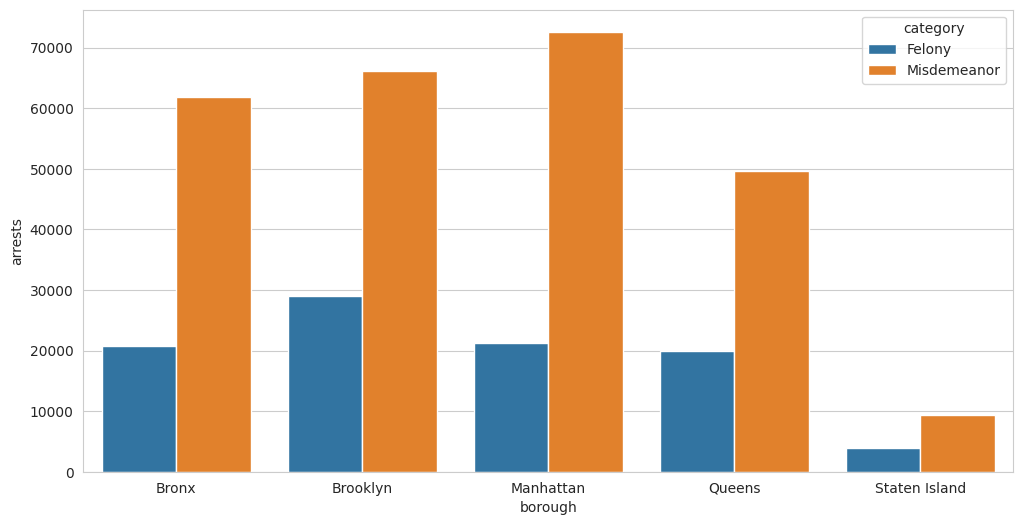

In [ ]:
sns.barplot(
    data=borough_arrests,
    x='borough',
    y='arrests',
    hue='category'
)


### From These Charts to Your Own Analysis

Working with dates will let you select comparison periods. Groupby will let you summarize arrests within those periods and across categories. Plotting will let you display the resulting patterns.

We begin by examining the original date column in `df`.


---

## Part 1: Understanding Datetime Objects

Our `ARREST_DATE` column contains dates stored as text. Let's see what happens when we try date operations on those values, then convert the column so we can filter dates, extract their parts, and calculate time differences.

### Check the data type

Last week we used `type()` to identify a Python object, such as a string or a DataFrame. A single pandas column is a **Series**.

- `type(df['ARREST_DATE'])` identifies the object as a Series.
- `df['ARREST_DATE'].dtype` describes how the values inside that column are stored.

Here, `object` is the column's storage type, and its date values are strings. After conversion, the column will have a datetime dtype.

In [ ]:
# Type of the column object
type(df['ARREST_DATE'])

# Data type of the values stored in the column
df['ARREST_DATE'].dtype

# First few date values
df['ARREST_DATE'].head()

### String vs Datetime: The Problem

Python compares strings character by character. The examples below compare February and December with different date formatting.

Then run each date-operation cell individually and read its error. Continue to the conversion cell afterward.

In [ ]:
# A date written as text is a string
type('12/03/2014')

# December comes after February
'2015-12-01' > '2015-02-01'

# February written without a leading zero: the string comparison gives True
'2015-2-01' > '2015-12-01'

In [ ]:
# Expected TypeError: compare text dates with a datetime value
df[df['ARREST_DATE'] >= pd.to_datetime(arg='2014-01-01')]


In [ ]:
# Expected AttributeError: extract years from the text column
df['ARREST_DATE'].dt.year


In [ ]:
# Expected TypeError: subtract the earliest and latest text values
df['ARREST_DATE'].max() - df['ARREST_DATE'].min()


### Converting to Datetime

Use `pd.to_datetime()` to convert strings to datetime objects.

In [ ]:
# Convert the column to datetime values
df['ARREST_DATE'] = pd.to_datetime(arg=df['ARREST_DATE'])

# Data type after conversion
df['ARREST_DATE'].dtype

# First few dates
df['ARREST_DATE'].head()

### The .dt Accessor: Your Gateway to Date Components

Once a column is datetime, you can use the `.dt` accessor to extract parts of the date.

**Think of `.dt` as unlocking date-specific operations:**

```python
df['date_column'].dt.year        # Extract year (2014, 2015, etc.)
df['date_column'].dt.month       # Extract month (1-12)
df['date_column'].dt.day         # Extract day (1-31)
df['date_column'].dt.day_name()  # Day of week ('Monday', 'Tuesday', etc.)
```

The converted column now supports these `.dt` operations.

In [ ]:
# Examples of .dt accessor
# Show on the whole column first
df['ARREST_DATE'].dt.year.head()

df['ARREST_DATE'].dt.month.head()

df['ARREST_DATE'].dt.day.head()

df['ARREST_DATE'].dt.day_name().head()


### Quick Check #1
Extract the year, month, and day of week from ARREST_DATE.
Store them in new columns called 'year', 'month', and 'day_of_week'.

Use the `.dt` accessor!

In [ ]:
# Your code here:




---

## Part 2: Understanding Time Periods

When analyzing trends over time, we often want to group dates into periods (months, quarters, years).

**The `.to_period()` method converts dates to time periods.**

### Keep the Year and Month Together

`.dt.month` gives the month number: January is `1` in every year. Grouping by this number combines the three Januaries in our dataset.

A `year_month` column keeps January 2013, January 2014, and January 2015 separate. The supplied code below labels each month with its first date, which also prepares it for the charts. We'll unpack chart preparation during the visualization lesson.

In [ ]:
# Combine the same month across years
df['month'] = df['ARREST_DATE'].dt.month
monthly_arrests = df.groupby(by=['month']).size().reset_index(name='monthly_arrests')
sns.lineplot(data=monthly_arrests, x='month', y='monthly_arrests')

### Create Monthly Periods

In [ ]:
# Label each calendar month with its first date (supplied chart preparation)
df['year_month'] = df['ARREST_DATE'].dt.to_period(freq='M').dt.to_timestamp()

# Original dates and their month labels
df[['ARREST_DATE', 'year_month']].head(10)

# Data type
df['year_month'].dtype

# Number of distinct months
df['year_month'].nunique()

# First and last month
df['year_month'].min()
df['year_month'].max()

In [ ]:
monthly_arrests = df.groupby(by=['year_month']).size().reset_index(name='monthly_arrests')

In [ ]:
sns.lineplot(data=monthly_arrests, x='year_month', y='monthly_arrests')

### Other Time Periods

The same supplied pattern can label each quarter (`'Q'`) or year (`'Y'`) with its first date.

In [ ]:
# Label each quarter and year with its first date
df['year_quarter'] = df['ARREST_DATE'].dt.to_period(freq='Q').dt.to_timestamp()
df['year_only'] = df['ARREST_DATE'].dt.to_period(freq='Y').dt.to_timestamp()

# Compare the different time labels
df[['ARREST_DATE', 'year_month', 'year_quarter', 'year_only']].head(10)

# Clean up demo columns
df = df.drop(columns=['year_quarter', 'year_only'])

### Quick Check #2

Use the quarterly pattern above for two parts:

1. How many unique quarters are in the dataset?
2. Count arrests per quarter and plot the trend as a line.

In [ ]:
# Your code here:




---

## Part 3: Exploratory Analysis - Finding the Pullback Period

Before we can study the pullback effect, we need to see it in the data!

Let's count arrests by month and visualize the trend to identify when enforcement dropped.

### Count Arrests by Month

In [ ]:
# Count arrests by month
monthly_arrests = df.groupby(by=['year_month']).size()
monthly_arrests

# Month with the fewest arrests
min_month = monthly_arrests.idxmin()
min_month

# Number of arrests in that month
min_arrests = monthly_arrests.min()
min_arrests

### Visualize the Trend

Let's plot monthly arrests to see the pullback visually using seaborn.

In [ ]:
# Convert to a DataFrame for the chart
monthly_df = monthly_arrests.reset_index(name='arrests')

sns.lineplot(data=monthly_df, x='year_month', y='arrests')

# What do you notice about the pattern?
# When do arrests drop sharply?

### Define the Pullback Period

Based on the visualization, we can see arrests drop sharply around December 2014 and stay low through early 2015.

**Research context**: Political tensions escalated in early December 2014, and the enforcement pullback lasted through February 2015.

In [ ]:
# Define the comparison window
pullback_start = pd.to_datetime(arg='2014-12-01')
pullback_end = pd.to_datetime(arg='2015-02-28')

# Start and end dates
pullback_start
pullback_end

# Type of one datetime value
type(pullback_start)

---

## Part 4: Filtering by Date Ranges

Now that we've identified the pullback period, let's filter the data to compare different time periods.

### Method 1: Using Comparison Operators

The straightforward way to filter by dates.

In [ ]:
# Baseline: before December 1, 2014
baseline = df[df['ARREST_DATE'] < pullback_start]

# Pullback: December 1, 2014 through February 28, 2015
pullback = df[(df['ARREST_DATE'] >= pullback_start) & (df['ARREST_DATE'] <= pullback_end)]

# Recovery: after February 28, 2015
recovery = df[df['ARREST_DATE'] > pullback_end]

# Arrest counts in the same order
len(baseline)
len(pullback)
len(recovery)

### Method 2: Using .between()

A cleaner way to filter for dates in a range.

In [ ]:
# Select the same pullback dates with .between()
pullback_between = df[df['ARREST_DATE'].between(left=pullback_start, right=pullback_end)]
len(pullback_between)

# Compare the two counts
len(pullback_between) == len(pullback)

# Another example: October 1 through December 31, 2014
q4_2014 = df[df['ARREST_DATE'].between(left=pd.to_datetime(arg='2014-10-01'), right=pd.to_datetime(arg='2014-12-31'))]
len(q4_2014)

### Quick Check #3
Filter the data for arrests that occurred in January 2015 only.
How many arrests were there?

Try both methods: comparison operators and `.between()`

In [ ]:
# Your code here:




---

## Part 5: Calculating Daily Rates

To fairly compare periods of different lengths, we need to calculate daily arrest rates.

### Understanding .days for Time Differences

When you subtract two datetime objects, you get a `timedelta` object. Use `.days` to get the number of days.

In [ ]:
# Subtracting datetime values gives a Timedelta
time_difference = pullback_start - df['ARREST_DATE'].min()
time_difference
type(time_difference)

# Use .days to get the number of days in each period
baseline_days = (pullback_start - df['ARREST_DATE'].min()).days
pullback_days = (pullback_end - pullback_start).days + 1  # Include both endpoints
recovery_days = (df['ARREST_DATE'].max() - pullback_end).days

# Baseline, pullback, and recovery lengths
baseline_days
pullback_days
recovery_days

### Calculate Daily Arrest Rates

In [ ]:
# Calculate daily rates for each period
baseline_daily = len(baseline) / baseline_days
pullback_daily = len(pullback) / pullback_days
recovery_daily = len(recovery) / recovery_days

# Average arrests per day: baseline, pullback, recovery
baseline_daily
pullback_daily
recovery_daily

### Understanding Percentage Change

**Percentage change formula:**

```
percentage_change = ((new_value - old_value) / old_value) × 100
```

**Example:**
- Old value: 100 arrests/day
- New value: 60 arrests/day
- Change: (60 - 100) / 100 = -0.40 = -40%

A negative percentage means a decrease.

In [ ]:
# Percentage change from baseline to pullback
pct_change = ((pullback_daily - baseline_daily) / baseline_daily) * 100
pct_change

# A negative value means the daily average decreased

### Quick Check #4
Calculate the percentage change in daily arrest rates from pullback to recovery.
Did enforcement return to baseline levels?

In [ ]:
# Your code here:




---

## Part 6: Creating Period Indicators

Instead of keeping three separate filtered datasets (baseline, pullback, recovery), we can create a single column that labels each arrest by its period. This makes groupby operations much easier.

**The goal**:
```python
# Add a 'period' column to label each arrest
# ARREST_DATE          period
# 2013-05-15      →    Baseline
# 2014-12-20      →    Pullback
# 2015-06-10      →    Recovery
```

### Introducing `.loc` for Conditional Assignment

To create this period column, we need to **assign different values to different rows based on a condition**. Pandas provides `.loc` for this.

**The `.loc` pattern for assignment:**
```python
df.loc[condition, 'column_name'] = value
```

- **condition**: Boolean statement - which rows to modify
- **'column_name'**: Which column to update
- **value**: What to assign to those rows

Let's start with a simpler example: creating just two periods.

In [ ]:
# Start with a default label
df['simple_period'] = 'Before Pullback'

# The condition selects rows; the column name selects what to update
df.loc[df['ARREST_DATE'] >= pullback_start, 'simple_period'] = 'During/After Pullback'

# Arrest counts for each label
df['simple_period'].value_counts()

### Creating Three Periods

Our visualization showed arrests recovered after February 2015. We need three distinct periods. We use `.loc` multiple times with different conditions.

In [ ]:
# Start with the earliest period as the default
df['period'] = 'Baseline'

# Update dates inside the pullback window
df.loc[df['ARREST_DATE'].between(left=pullback_start, right=pullback_end), 'period'] = 'Pullback'

# Update dates after the pullback window
df.loc[df['ARREST_DATE'] > pullback_end, 'period'] = 'Recovery'

# Counts for each label
df['period'].value_counts()

In [ ]:
# Each labeled group should match its earlier filtered table
(df['period'] == 'Baseline').sum() == len(baseline)
(df['period'] == 'Pullback').sum() == len(pullback)
(df['period'] == 'Recovery').sum() == len(recovery)

# Start with the default, then update rows that meet each condition

---

## Part 7: Differential Impact by Arrest Type

**Research Question**: Did all arrest types drop equally during the pullback, or were some affected more than others?

**Hypothesis**: Discretionary arrests (misdemeanors) should drop more than mandatory arrests (felonies).

### Compare Felonies vs Misdemeanors

Let's see how different offense levels changed during the pullback.

### Introducing `.iloc` for Position-Based Access

Before we analyze arrest types, we need a way to access specific rows from our grouped results by their **position** (1st, 2nd, 3rd...).

**`.iloc` allows position-based indexing:**
```python
df.iloc[0]      # First row
df.iloc[1]      # Second row
df.iloc[-1]     # Last row
df.iloc[0:3]    # First 3 rows
```

This is useful when working with grouped data where we know the order of groups.

In [ ]:
# Count arrests by period and law category
period_lawcat = df.groupby(by=['period', 'LAW_CAT_CD']).size()
period_lawcat

# Groups are ordered alphabetically:
# Position 0: Baseline, F
# Position 1: Baseline, M
# Position 2: Pullback, F
# Position 3: Pullback, M
# Position 4: Recovery, F
# Position 5: Recovery, M

In [ ]:
# Access the groups by position
baseline_felony = period_lawcat.iloc[0]
baseline_misdemeanor = period_lawcat.iloc[1]
pullback_felony = period_lawcat.iloc[2]
pullback_misdemeanor = period_lawcat.iloc[3]

# Baseline felony and misdemeanor counts
baseline_felony
baseline_misdemeanor

# Pullback felony and misdemeanor counts
pullback_felony
pullback_misdemeanor

In [ ]:
baseline_felony



In [ ]:
baseline_days

In [ ]:
# Average daily arrests in each group
baseline_felony_rate = baseline_felony / baseline_days
baseline_misdemeanor_rate = baseline_misdemeanor / baseline_days
pullback_felony_rate = pullback_felony / pullback_days
pullback_misdemeanor_rate = pullback_misdemeanor / pullback_days

# Percentage changes from baseline to pullback
felony_pct_change = ((pullback_felony_rate - baseline_felony_rate) / baseline_felony_rate) * 100
misdemeanor_pct_change = ((pullback_misdemeanor_rate - baseline_misdemeanor_rate) / baseline_misdemeanor_rate) * 100

# Felony change, then misdemeanor change
felony_pct_change
misdemeanor_pct_change

### Visualize the Comparison

In [ ]:
# Create plot data using groupby and reset_index
# period_lawcat is already grouped - just need to convert to DataFrame
plot_data = period_lawcat.reset_index()
plot_data.columns = ['Period', 'LAW_CAT_CD', 'Arrests']



In [ ]:
# Map LAW_CAT_CD to friendly names for the plot
plot_data['Category'] = 'Felony'
plot_data.loc[plot_data.LAW_CAT_CD=='M'  , 'Category'] = 'Misdemeanor'




In [ ]:

# Plot 1: Absolute counts by period
sns.barplot(data=plot_data, x='Period', y='Arrests', hue='Category')



In [ ]:
# Plot 2: Percentage change from baseline
pct_df = pd.DataFrame({
    'Category': ['Felony', 'Misdemeanor'],
    'Pct_Change': [felony_pct_change, misdemeanor_pct_change]
})

sns.barplot(data=pct_df, y='Category', x='Pct_Change')


**Interpretation**:
- Which type of arrest dropped more during the pullback?
- What does this tell us about discretionary vs. mandatory policing?
- Did enforcement return to baseline levels after the pullback?

---

## Hands-On Exercises

Work through these exercises and be ready to explain your code and results.

## Exercise 1: Day of Week Analysis

**Task:** Calculate which day of the week has the highest arrest count. Did this pattern change during the pullback?

In [ ]:
# Exercise 1: Which day of the week has the most arrests?
# Note: this needs the 'day_of_week' column you made in Quick Check #1

day_counts = None  # YOUR CODE HERE - group by day_of_week, use .size(), sort descending

# YOUR OUTPUT HERE

# Now check whether the pattern changed during the pullback
day_period = None  # YOUR CODE HERE - group by ['period', 'day_of_week'], then .size().reset_index(name='arrests')

# YOUR PLOT HERE - sns.barplot with x='day_of_week', y='arrests', hue='period'

## Exercise 2: Quarterly Analysis

**Task:** Create quarterly periods, count arrests by quarter, and plot the trend.

In [ ]:
# Exercise 2: Count arrests by quarter and plot the trend
# Use the supplied quarterly date-label pattern from Part 2

df['year_quarter'] = None      # YOUR CODE HERE
quarterly_arrests = None       # YOUR CODE HERE - group by year_quarter, .size().reset_index(name='arrests')

# YOUR OUTPUT HERE

# YOUR PLOT HERE - sns.lineplot

## Exercise 3: Recovery Speed

**Task:** Calculate how long it took for monthly arrests to return to at least 90% of the baseline average.

This one is harder than the others. Take it one step at a time.

In [ ]:
# Exercise 3: How many months until arrests returned to 90% of baseline?

baseline_monthly = None  # YOUR CODE HERE - monthly arrest counts during the baseline period
baseline_avg = None      # YOUR CODE HERE - average of those monthly counts
threshold = None         # YOUR CODE HERE - 90% of baseline_avg

# YOUR OUTPUT HERE - show baseline_avg and threshold

recovery_monthly = None  # YOUR CODE HERE - monthly arrest counts during the recovery period

# YOUR CODE HERE - find the first month at or above threshold, and count how many months came before it

## Exercise 4: Borough Analysis

**Task:** Investigate whether different boroughs experienced the pullback differently.

In [ ]:
# Exercise 4: Did the pullback hit some boroughs harder than others?

borough_period = None  # YOUR CODE HERE - group by ['ARREST_BORO', 'period'], .size().reset_index(name='arrests')

# YOUR OUTPUT HERE

# The periods have different lengths, so compare daily rates, not raw counts.
# For each borough: baseline rate = baseline count / baseline_days
#                   pullback rate = pullback count / pullback_days
#                   percentage change = ((pullback rate - baseline rate) / baseline rate) * 100

# YOUR CODE HERE

# YOUR PLOT HERE - sns.barplot of percentage change by borough

## Exercise 5: Most Common Offense Descriptions

**Task:** Find the top 5 most common offense descriptions for felonies and for misdemeanors.

In [ ]:
# Exercise 5: Top 5 offense descriptions by offense level
# LAW_CAT_CD is 'F' for felony and 'M' for misdemeanor

felony_offenses = None       # YOUR CODE HERE - filter to felonies, group by OFNS_DESC, .size(), sort descending
misdemeanor_offenses = None  # YOUR CODE HERE - same thing for misdemeanors

# YOUR OUTPUT HERE

# YOUR OUTPUT HERE

## Exercise 6: Pullback Analysis for a Specific Offense

**Task:** Take the most common felony offense from Exercise 5 and analyze how it changed during the pullback. Did it drop more or less than the overall average of about 26%?

In [ ]:
# Exercise 6: How did the most common felony offense change during the pullback?

most_common_felony = None  # YOUR CODE HERE - the first index value from felony_offenses
offense_df = None          # YOUR CODE HERE - filter df to just that offense
offense_by_period = None   # YOUR CODE HERE - group by 'period', .size()

# YOUR OUTPUT HERE

# YOUR CODE HERE - daily rates for baseline and pullback, then percentage change

# Compare your answer to the overall decrease of about 26.4%.
# Dropping MORE than average suggests a more discretionary offense type.

## Summary

Today you learned key datetime operations:

1. **Converting text to dates** with `pd.to_datetime()`
2. **Extracting date components** using the `.dt` accessor
3. **Creating time periods** with `.dt.to_period()`
4. **Filtering by date ranges** using comparison operators and `.between()`
5. **Calculating time differences** using `.days`
6. **Creating period indicators** using `.loc` assignment
7. **Grouping by multiple categories** including time periods

### Key Datetime Principles:

- Always convert string dates to datetime using `pd.to_datetime()`
- Use `.dt` accessor for all date operations
- Use `.to_period('M')` for proper monthly aggregation (not just `.dt.month`)
- Use `.between()` for cleaner date range filtering
- Calculate daily rates when comparing periods of different lengths
- Use percentage change formula: `((new - old) / old) * 100`

### Remember:

- Datetime operations enable before/after comparisons
- Natural experiments (like the NYPD pullback) create opportunities for causal analysis
- Different categories (boroughs, offense types) can respond differently to the same event
- Visualization helps reveal patterns that numbers alone might hide